# Lecture 4 — Class Exercise
## Scatter & Bubble Charts: Gapminder

> **Push to:** `week04/lecture04_exercise.ipynb`

**Rules:**
1. Colour used **sparingly** — one categorical variable, no rainbow
2. If showing all continents, either use accessible palette OR grey all + highlight one
3. `size_max` set when using bubble size
4. Log scale for GDP per capita
5. Insight title

---


In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# The complete 1,704-row Gapminder sample is bundled with Plotly.
df = px.data.gapminder()
assert {'country','continent','year','lifeExp','gdpPercap','pop'} <= set(df.columns)
print(f'Loaded {len(df)} records from {df.country.nunique()} countries, years {df.year.min()}–{df.year.max()}.')
display(df.head())

Loaded 1704 records from 142 countries, years 1952–2007.


,country,continent,year,lifeExp,pop,gdpPercap,iso_alpha,iso_num
0,Afghanistan,Asia,1952,28.801,8425333,779.445314,AFG,4
1,Afghanistan,Asia,1957,30.332,9240934,820.853030,AFG,4
2,Afghanistan,Asia,1962,31.997,10267083,853.100710,AFG,4
3,Afghanistan,Asia,1967,34.020,11537966,836.197138,AFG,4
4,Afghanistan,Asia,1972,36.088,13079460,739.981106,AFG,4


In [2]:
# Explore the full dataset before choosing a continent.
print('Available years:', sorted(df.year.unique()))
print('Continents:', ', '.join(sorted(df.continent.unique())))
print('Rows for 2007:', len(df[df.year == 2007]))
print('Null values:', df[['country','continent','year','lifeExp','gdpPercap','pop']].isna().sum().to_dict())

Available years: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Continents: Africa, Americas, Asia, Europe, Oceania
Rows for 2007: 142
Null values: {'country': 0, 'continent': 0, 'year': 0, 'lifeExp': 0, 'gdpPercap': 0, 'pop': 0}


## Task 1 — Scatter: life expectancy change over time

**What to build:** A scatter showing **GDP per capita vs life expectancy** for **two years** (2002 and 2007) to show how both moved — use **colour for year** (just 2 colours), **one continent only**.

Choose any continent except Africa (that was the example). Highlight the change direction.

> 💡 Filter: `df.loc[df['continent'] == 'YOUR_CHOICE']` then filter years


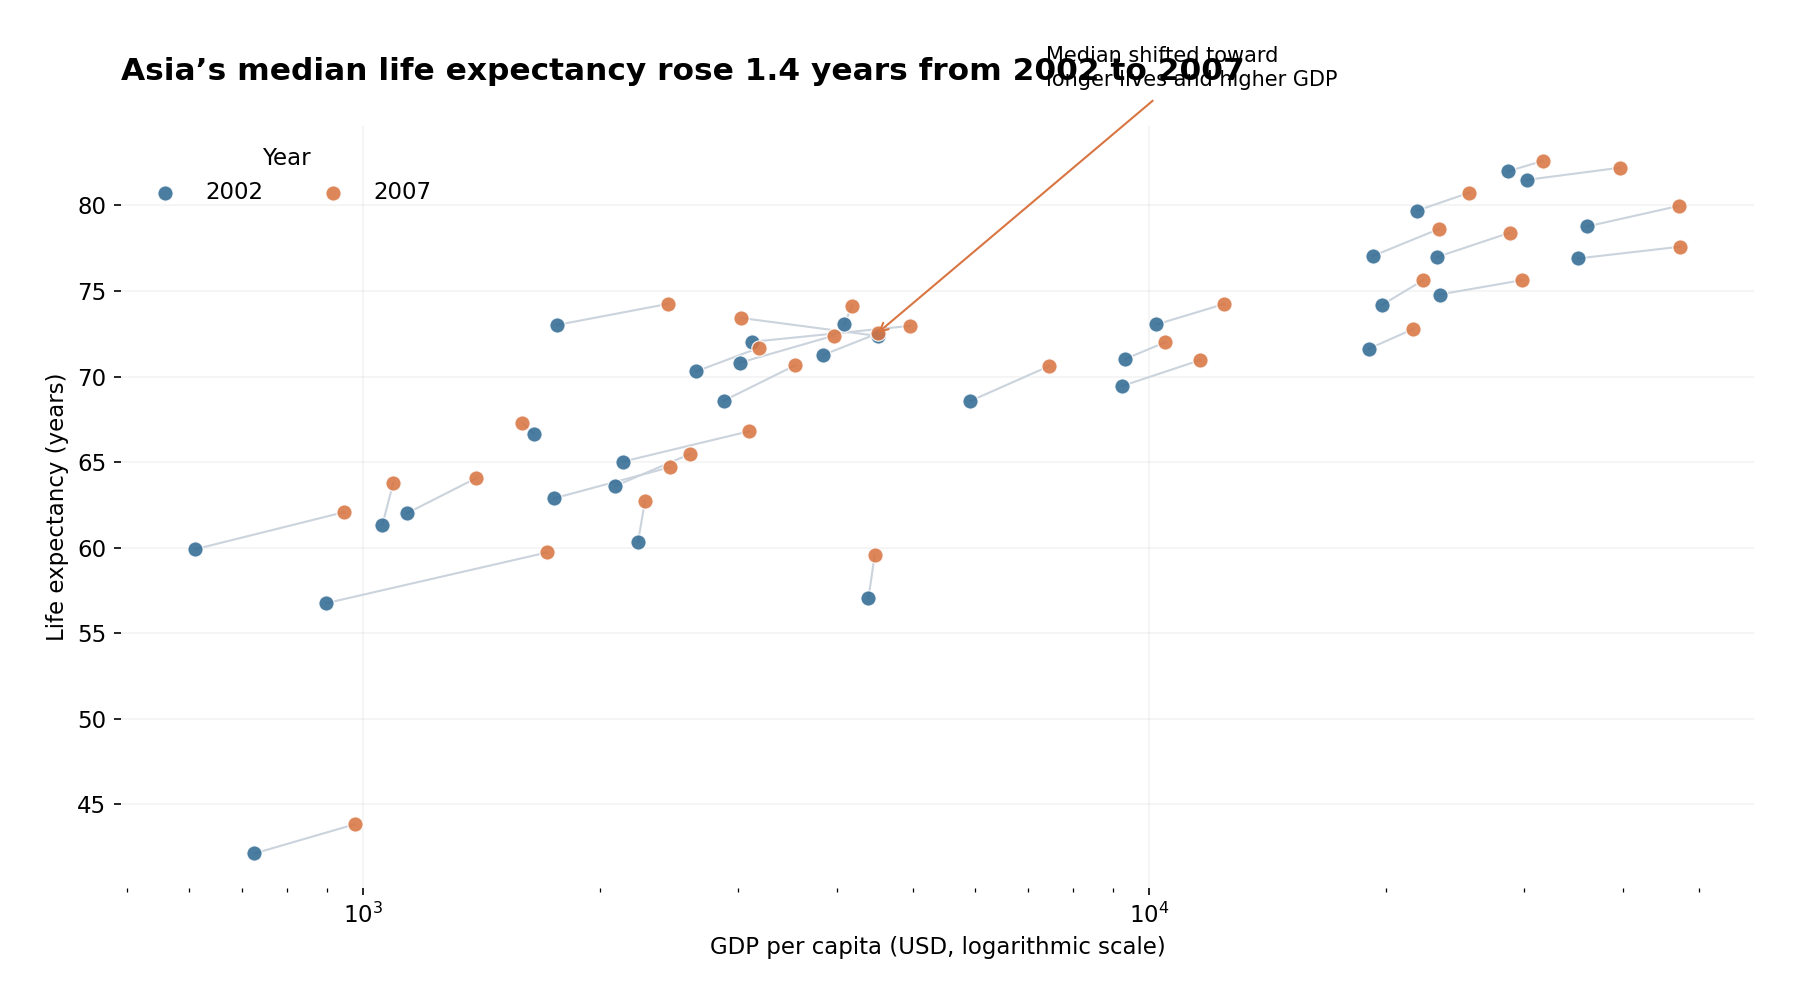

Asia: median life expectancy 71.03 → 72.40 years; median GDP/person increased 9.3%.


In [3]:
# Task 1 — Compare 2002 and 2007 within Asia, with arrows/lines for changes.
continent = 'Asia'  # The assignment permits any continent except Africa.
selected = df[(df.continent == continent) & (df.year.isin([2002, 2007]))].copy()
selected['Period'] = selected['year'].astype(str)
assert selected.country.nunique() == 33 and len(selected) == 66

median_life = selected.groupby('year').lifeExp.median()
median_gdp = selected.groupby('year').gdpPercap.median()
life_gain = median_life.loc[2007] - median_life.loc[2002]
gdp_change = (median_gdp.loc[2007]/median_gdp.loc[2002]-1)*100

fig1 = go.Figure()
# Draw a subtle connector for each country, to reveal its movement over time.
for country, subset in selected.groupby('country'):
    subset = subset.sort_values('year')
    fig1.add_trace(go.Scatter(
        x=subset.gdpPercap, y=subset.lifeExp, mode='lines',
        line=dict(color='#CCD2D9', width=1.2),
        hoverinfo='skip', showlegend=False))

# Distinguish the two years using only two deliberate colors.
colors = {'2002': '#326B94', '2007': '#D87542'}
for period in ['2002', '2007']:
    points = selected[selected.Period == period]
    fig1.add_trace(go.Scatter(
        x=points.gdpPercap, y=points.lifeExp,
        mode='markers', name=period,
        marker=dict(color=colors[period], size=9, opacity=0.86,
                    line=dict(color='white', width=0.6)),
        customdata=points.country.to_numpy(),
        hovertemplate='%{customdata}<br>GDP per person: $%{x:,.0f}<br>Life expectancy: %{y:.1f} years<extra>'+period+'</extra>'))

fig1.add_annotation(
    x=median_gdp.loc[2007], y=median_life.loc[2007],
    text='Median moved toward<br>longer lives and higher GDP',
    showarrow=True, ax=85, ay=-70, arrowhead=2,
    arrowcolor='#D87542', font=dict(size=12, color='#374151'),
    bgcolor='rgba(255,255,255,0.88)', borderpad=5)
fig1.update_layout(
    title=dict(text=f'Asia’s median life expectancy rose {life_gain:.1f} years from 2002 to 2007', x=0.02),
    xaxis=dict(title='GDP per capita (USD, logarithmic scale)', type='log',
               showgrid=True, gridcolor='#F0F2F5', zeroline=False),
    yaxis=dict(title='Life expectancy (years)', showgrid=True,
               gridcolor='#F0F2F5', zeroline=False),
    height=620, width=1100, template='plotly_white',
    legend=dict(title='Year', orientation='h', x=0.78, y=1.08),
    margin=dict(l=85,r=70,t=100,b=75),
    paper_bgcolor='white', plot_bgcolor='white',
    font=dict(family='Arial', size=13, color='#334155'))
assert fig1.layout.xaxis.type == 'log'
assert len([t for t in fig1.data if t.mode == 'markers']) == 2
fig1.show()
print(f'{continent}: median life expectancy {median_life.loc[2002]:.2f} → {median_life.loc[2007]:.2f} years; median GDP/person increased {gdp_change:.1f}%.')

## Task 2 — Bubble chart: tell a story

**What to build:** A bubble chart (full 2007 dataset, all countries) where:
- x = GDP per capita (log scale)
- y = life expectancy
- size = population
- colour = ONE continent highlighted (your choice), all others grey
- At least one annotation explaining the highlighted group's story

> This is the grey-and-highlight technique applied to a bubble chart.


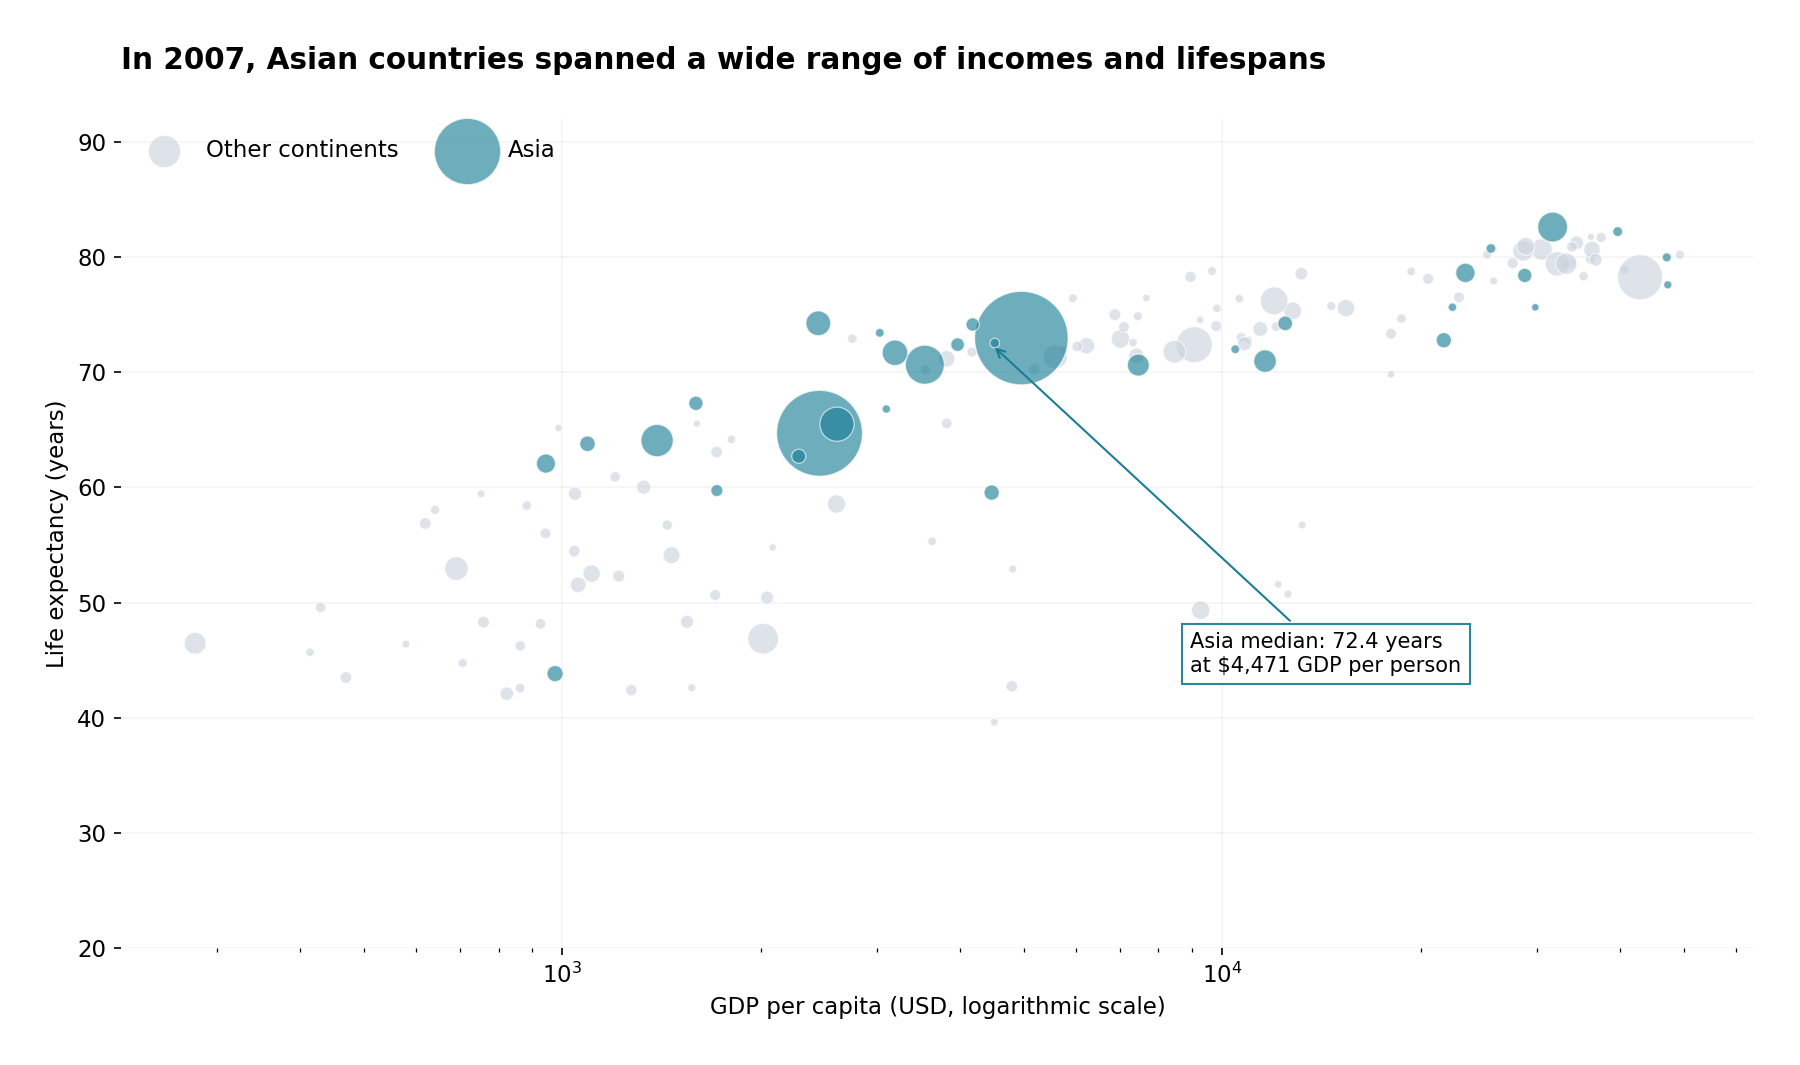

142 countries included; 33 Asian countries highlighted. Asia median GDP/person: $4,471; median life expectancy: 72.4 years.


In [4]:
# Task 2 — Full Gapminder sample (2007); highlight Asia against grey context.
df_2007 = df[df.year == 2007].copy()
assert len(df_2007) == df.country.nunique() == 142
highlight = 'Asia'
df_2007['Highlight'] = df_2007.continent.apply(
    lambda c: highlight if c == highlight else 'Other continents')
# Draw grey bubbles first so coloured bubbles remain visible in front.
df_2007['Highlight'] = pd.Categorical(
    df_2007['Highlight'], categories=['Other continents', highlight], ordered=True)

asia_2007 = df_2007[df_2007.continent == highlight]
median_asia_gdp = asia_2007.gdpPercap.median()
median_asia_life = asia_2007.lifeExp.median()

fig2 = px.scatter(
    df_2007, x='gdpPercap', y='lifeExp', size='pop',
    color='Highlight', hover_name='country',
    hover_data={'continent':True, 'pop':':,', 'gdpPercap':':,.0f', 'lifeExp':':.1f', 'Highlight':False},
    color_discrete_map={'Other continents':'#CED4DB', 'Asia':'#197E96'},
    opacity=0.75, size_max=50, log_x=True,
    labels={'gdpPercap':'GDP per capita (USD, logarithmic scale)',
            'lifeExp':'Life expectancy (years)', 'pop':'Population', 'Highlight':''},
    title='In 2007, Asian countries spanned a wide range of incomes and lifespans')
fig2.add_annotation(
    x=median_asia_gdp, y=median_asia_life,
    text=f'Asia median: {median_asia_life:.1f} years<br>at ${median_asia_gdp:,.0f} GDP per person',
    showarrow=True, arrowhead=2, ax=120, ay=-95,
    arrowcolor='#197E96', bordercolor='#197E96', borderwidth=1,
    bgcolor='rgba(255,255,255,0.92)', font=dict(color='#24556A',size=12),
    borderpad=6)
fig2.update_layout(
    width=1100, height=650, template='plotly_white',
    title=dict(x=0.02),
    xaxis=dict(type='log', showgrid=True, gridcolor='#F0F2F5'),
    yaxis=dict(showgrid=True, gridcolor='#F0F2F5', range=[20,92]),
    legend=dict(title=None, orientation='h', y=1.08, x=0.6),
    margin=dict(l=85,r=80,t=100,b=80),
    paper_bgcolor='white', plot_bgcolor='white',
    font=dict(family='Arial',size=13,color='#334155'))
fig2.update_traces(marker=dict(line=dict(color='#FFFFFF', width=0.6)))
assert fig2.layout.xaxis.type == 'log'
assert len(fig2.data) == 2 and sum(len(trace.x) for trace in fig2.data) == 142
fig2.show()
print(f'{len(df_2007)} countries included; {len(asia_2007)} Asian countries highlighted. Asia median GDP/person: ${median_asia_gdp:,.0f}; median life expectancy: {median_asia_life:.1f} years.')

### Interpretation and design choices

- **Task 1:** A two-year scatter for **Asia** (not Africa), with two colours and a faint segment joining each country's 2002 and 2007 observations. The x-axis is logarithmic to keep very different incomes readable. The annotation identifies the direction of the region’s median shift.
- **Task 2:** Every country in **2007** is included. Population controls bubble area (`size_max=50`); Asia is teal, while all other continents are grey. The annotation reports actual Asian medians instead of an arbitrary location.
- Both charts use **insight titles**, restrained colours, lightweight gridlines and informative hover labels.

*Source: Plotly's built-in Gapminder data. Values reflect the dataset supplied with Plotly, not current 2026 statistics.*